# Práctica 2.2 — Máquinas de soporte vectorial: la calle más ancha

Este cuaderno acompaña la clase «Máquinas de soporte vectorial» (SVM, por *support vector machines*) y usa **los mismos hogares** de las prácticas de árbol, random forest y k vecinos, para comparar los modelos. Sigue el recorrido de la clase:

1. Datos y partición · 2. **El margen y los vectores de soporte** · 3. Escalar · 4. **Margen suave: el efecto de C** · 5. **Kernel RBF y gamma** · 6. Elegir kernel, C y gamma con validación cruzada · 7. Del puntaje a la probabilidad · 8. **Métricas** y curvas ROC frente a los demás modelos · 9. Entrenamiento frente a prueba

**Datos.** `datos/2-2-hogares-subsidio.xlsx`: 1.200 hogares **simulados con fines didácticos**; la variable objetivo es **pobre (Sí/No)**.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, sube la carpeta datos/ al entorno
SEMILLA = 42
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

## 1. Datos y partición

La misma preparación, semilla y partición estratificada 75/25 de las otras prácticas. Se separan también las dos variables del plano de la clase: el ingreso por persona y la educación de quien encabeza el hogar.

In [3]:
hog = pd.read_excel(DATOS / '2-2-hogares-subsidio.xlsx', sheet_name='hogares')
hog['es_pobre'] = (hog['pobre'] == 'Sí').astype(int)
def preparar(d):
    X = d[['personas', 'menores_5', 'adultos_mayores', 'educacion_jefe', 'ocupados', 'ingreso_pc', 'cuartos', 'hacinamiento']].copy()
    for c in ['jefe_mujer', 'acueducto', 'piso_tierra', 'internet']:
        X[c] = (d[c] == 'Sí').astype(int)
    X['rural'] = (d['zona'] == 'Rural').astype(int)
    return X.join(pd.get_dummies(d[['tipo_municipio', 'regimen_salud']], dtype=int)).astype(float)
X, y = preparar(hog), hog['es_pobre']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=SEMILLA, stratify=y)
print(f'{len(hog)} hogares, {y.mean():.1%} pobres · entrenamiento {len(Xtr)} · prueba {len(Xte)} · {X.shape[1]} variables')
X2tr, X2te = Xtr[['ingreso_pc', 'educacion_jefe']], Xte[['ingreso_pc', 'educacion_jefe']]   # las dos variables del plano

def metricas(yv, p, u=0.5):
    h = (p >= u).astype(int)
    return {'exactitud': accuracy_score(yv, h), 'precisión': precision_score(yv, h, zero_division=0), 'sensibilidad': recall_score(yv, h),
            'F1': f1_score(yv, h), 'AUC': roc_auc_score(yv, p) if np.std(p) > 0 else 0.5}
def matriz(ax, yv, p, titulo, u=0.5):
    m = confusion_matrix(yv, (p >= u).astype(int))
    ax.imshow([[0, 1], [1, 0]], cmap=LinearSegmentedColormap.from_list('mc', ['#e8f2fc', '#fbe3e3']), vmin=0, vmax=1)
    for (i, j), r in zip([(0, 0), (0, 1), (1, 0), (1, 1)], ['VN', 'FP', 'FN', 'VP']):
        ax.text(j, i, f'{r}\n{m[i, j]}', ha='center', va='center', fontsize=15, color=TINTA)
    ax.set_xticks([0, 1], ['no pobre', 'pobre']); ax.set_yticks([0, 1], ['no pobre', 'pobre'])
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real'); ax.set_title(titulo); ax.grid(False)

# rejilla del plano ingreso × educación (ingreso hasta 1,5 millones de pesos por persona)
gi, ge = np.meshgrid(np.linspace(0, 1_500_000, 160), np.linspace(0, 20, 120))
rejilla = pd.DataFrame({'ingreso_pc': gi.ravel(), 'educacion_jefe': ge.ravel()})
def dibujar_mapa(ax, modelo, titulo, puntos=True):
    p = modelo.predict_proba(rejilla)[:, 1].reshape(gi.shape)
    ax.contourf(gi / 1000, ge, p, levels=np.linspace(0, 1, 11), cmap=DIV, alpha=.55)
    ax.contour(gi / 1000, ge, p, levels=[.5], colors=TINTA, linewidths=1.5)
    if puntos:
        v = X2tr[X2tr['ingreso_pc'] <= 1_500_000].iloc[:250]
        ax.scatter(v['ingreso_pc'] / 1000, v['educacion_jefe'] + rng_j.uniform(-.3, .3, len(v)), s=10,
                   c=np.where(ytr.loc[v.index] == 1, NARANJA, AZUL), edgecolor='white', lw=.4)
    ax.set_xlim(0, 1500); ax.set_ylim(0, 20); ax.set_title(titulo)
    ax.set_xlabel('Ingreso por persona (miles de pesos)'); ax.set_ylabel('Años de educación del jefe')
rng_j = np.random.default_rng(SEMILLA)

def dibujar_calle(ax, modelo, titulo, datos=None, yv=None):
    """frontera (puntaje 0), bordes de la calle (−1 y 1) y vectores de soporte de un SVC en el plano ingreso × educación"""
    f = modelo.decision_function(rejilla).reshape(gi.shape)
    ax.contourf(gi / 1000, ge, f, levels=[-99, -1, 0, 1, 99], colors=['#dbe8f8', '#eef3fb', '#fdf0e6', '#fbe0cc'])
    ax.contour(gi / 1000, ge, f, levels=[-1, 0, 1], colors=[GRIS, TINTA, GRIS], linestyles=['--', '-', '--'], linewidths=[1.2, 2, 1.2])
    d = X2tr if datos is None else datos; yy = ytr if yv is None else yv
    v = d[d['ingreso_pc'] <= 1_500_000]
    ax.scatter(v['ingreso_pc'] / 1000, v['educacion_jefe'] + (0 if datos is not None else rng_j.uniform(-.3, .3, len(v))), s=10 if datos is None else 22,
               c=np.where(yy.loc[v.index] == 1, NARANJA, AZUL), edgecolor='white', lw=.4)
    sv = d.iloc[modelo[-1].support_]; sv = sv[sv['ingreso_pc'] <= 1_500_000]
    if len(sv) < 30:
        ax.scatter(sv['ingreso_pc'] / 1000, sv['educacion_jefe'], s=140, facecolor='none', edgecolor=TINTA, lw=1.6, label='vectores de soporte'); ax.legend(loc='upper right')
    ax.set_xlim(0, 1500); ax.set_ylim(0, 20); ax.set_title(titulo)
    ax.set_xlabel('Ingreso por persona (miles de pesos)'); ax.set_ylabel('Años de educación del jefe')

1200 hogares, 32.8% pobres · entrenamiento 900 · prueba 300 · 19 variables


Es la misma base de las otras prácticas de clasificación: **1.200 hogares, el 32,8 % pobres**, con 900 para entrenar y 300 para la prueba, y las mismas 19 variables. Además de las funciones de métricas, matriz y mapas, se define `dibujar_calle`, que pinta la frontera (puntaje 0), los bordes de la calle (puntajes −1 y 1) y los vectores de soporte.

## 2. El margen y los vectores de soporte

Primero, un caso que **sí** se puede separar con una recta: se toman 60 hogares de entrenamiento que quedan lejos de la frontera de un SVM lineal. Entre todas las rectas que los separan, el SVM elige la que deja **la calle más ancha** (el margen). Un C muy grande obliga a no aceptar errores (margen duro).

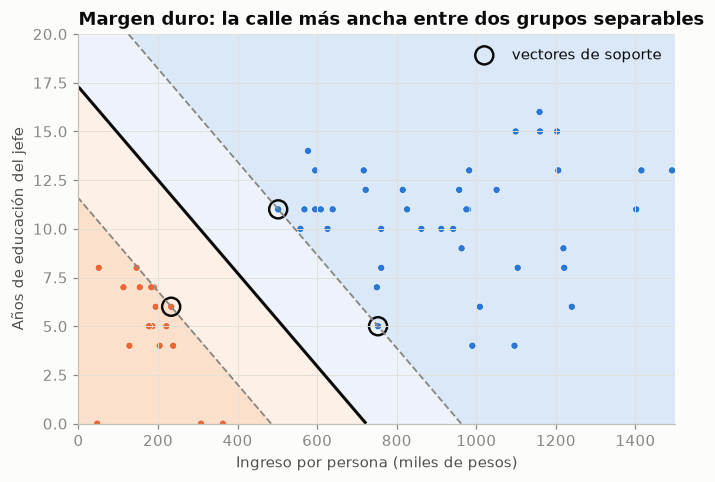

60 hogares · vectores de soporte: 3


,ingreso_pc,educacion_jefe,pobre
721,"502,000.000",11.000,No
1188,"753,000.000",5.000,No
729,"233,000.000",6.000,Sí


In [4]:
lineal = make_pipeline(StandardScaler(), SVC(kernel='linear', C=1)).fit(X2tr, ytr)
lejos = X2tr[(np.where(ytr == 1, 1, -1) * lineal.decision_function(X2tr) >= 1) & (X2tr['ingreso_pc'] <= 1_500_000)].iloc[:60]
duro = make_pipeline(StandardScaler(), SVC(kernel='linear', C=1000)).fit(lejos, ytr.loc[lejos.index])
fig, ax = plt.subplots(figsize=(7, 4.6))
dibujar_calle(ax, duro, 'Margen duro: la calle más ancha entre dos grupos separables', lejos, ytr.loc[lejos.index]); plt.show()
print(f'{len(lejos)} hogares · vectores de soporte: {len(duro[-1].support_)}')
lejos.iloc[duro[-1].support_].assign(pobre=ytr.loc[lejos.index].iloc[duro[-1].support_].map({1: 'Sí', 0: 'No'}).values)

Los 60 hogares se separan con una recta, y el SVM elige la que deja la calle más ancha. Solo **3 hogares** quedan sobre los bordes: son los **vectores de soporte**.

- Dos no pobres: 502.000 pesos y 11 años de educación, y 753.000 pesos y 5 años.
- Un pobre: 233.000 pesos y 6 años.

Solo esos tres definen la frontera. Si se movieran o se quitaran los otros 57 hogares (sin entrar en la calle), la frontera sería la misma. La frontera baja hacia la derecha: con más ingreso, basta menos educación para quedar del lado «no pobre».

## 3. Escalar

El SVM también mide distancias (el ancho de la calle y, con kernel, el parecido entre hogares), así que el ingreso en pesos aplastaría a la educación en años. Se compara un SVM con kernel RBF sin escalar y con las variables escaladas.

In [5]:
for nombre, m in [('sin escalar', SVC(kernel='rbf', C=1, gamma=1)), ('escaladas', make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1, gamma=1)))]:
    m.fit(X2tr, ytr)
    print(f'SVM RBF (2 variables) {nombre:12s}: exactitud en prueba {accuracy_score(yte, m.predict(X2te)):.3f} · vectores de soporte {len((m if nombre == "sin escalar" else m[-1]).support_)}')

SVM RBF (2 variables) sin escalar : exactitud en prueba 0.683 · vectores de soporte 892
SVM RBF (2 variables) escaladas   : exactitud en prueba 0.913 · vectores de soporte 316


Sin escalar, el SVM con kernel RBF **no aprende nada útil**:

- **Sin escalar:** exactitud en prueba **0,683**, apenas por encima de la línea base (0,673). Usa **892 de los 900 hogares** como vectores de soporte.
- **Con las variables escaladas:** exactitud **0,913**, con 316 vectores de soporte.

Con el ingreso en pesos, cualquier par de hogares queda «lejísimos» y el kernel no ve parecidos entre ellos. Como en kNN, escalar es indispensable.

## 4. Margen suave: el efecto de C

Con los datos reales ninguna recta separa a todos. El **margen suave** permite hogares dentro de la calle o del lado equivocado, pero los castiga; **C** dice cuánto. C pequeño: calle ancha y tolerante. C grande: calle angosta, que se ciñe al entrenamiento.

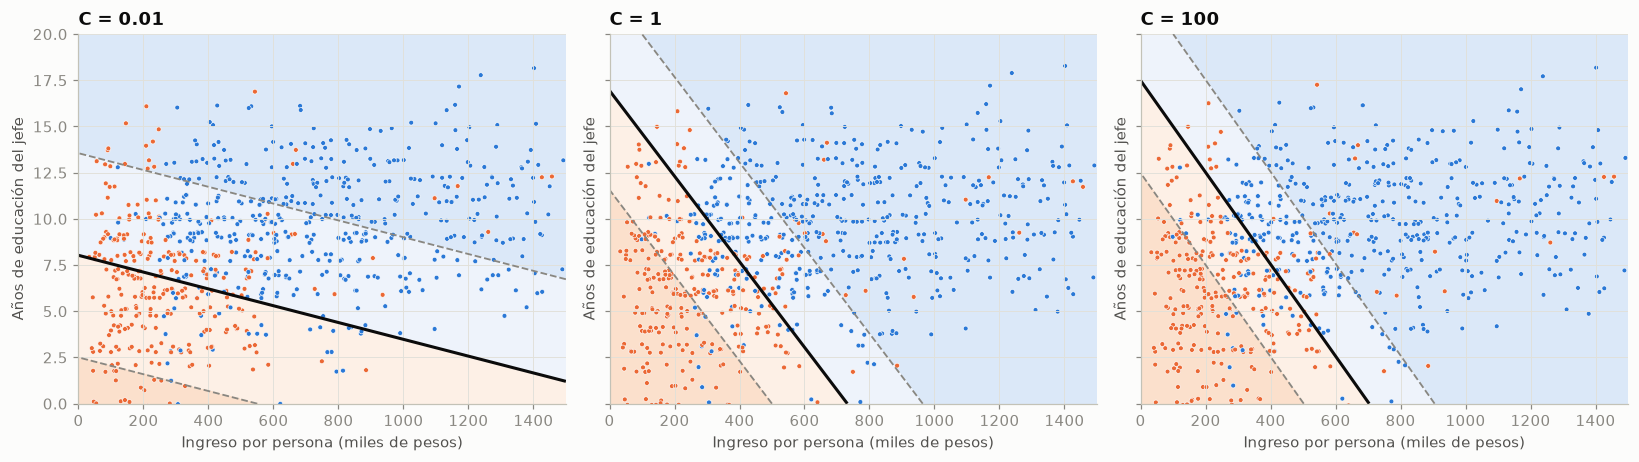

,ancho de la calle (desv.),vectores de soporte,dentro de la calle,exactitud entr.,exactitud prueba
C,,,,,
0.010,1.833,544,520,0.813,0.810
1.000,0.441,320,292,0.884,0.867
100.000,0.383,298,266,0.882,0.870


In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
filas = []
for ax, C in zip(axs, [0.01, 1, 100]):
    m = make_pipeline(StandardScaler(), SVC(kernel='linear', C=C)).fit(X2tr, ytr)
    dibujar_calle(ax, m, f'C = {C}')
    f = m.decision_function(X2tr)
    filas.append({'C': C, 'ancho de la calle (desv.)': 2 / np.linalg.norm(m[-1].coef_), 'vectores de soporte': len(m[-1].support_),
                  'dentro de la calle': int((np.abs(f) < 1).sum()), 'exactitud entr.': accuracy_score(ytr, m.predict(X2tr)), 'exactitud prueba': accuracy_score(yte, m.predict(X2te))})
plt.tight_layout(); plt.show()
pd.DataFrame(filas).set_index('C')

La tabla y los mapas muestran el papel de **C**:

| C | Ancho de la calle (desv.) | Vectores de soporte | Hogares dentro de la calle | Exactitud en prueba |
|---|---|---|---|---|
| 0,01 | 1,83 | 544 | 520 | 0,810 |
| 1 | 0,44 | 320 | 292 | 0,867 |
| 100 | 0,38 | 298 | 266 | 0,870 |

- **C = 0,01:** la calle es tan ancha que más de la mitad de los hogares quedan dentro. La frontera casi solo usa la educación (queda casi horizontal) y el modelo **subajusta**: 0,813 en entrenamiento y 0,810 en prueba.
- **C = 1 y C = 100:** la calle se angosta y la frontera se inclina para usar también el ingreso. Entre los dos casi no hay diferencia (0,867 y 0,870 en prueba).

Con una frontera recta y dos variables hay poco que sobreajustar. C pesa más con kernels flexibles, como se ve en la siguiente sección.

## 5. Kernel RBF y gamma

El **kernel** permite fronteras curvas: equivale a llevar los datos a un espacio con más dimensiones, donde una recta sí separa, sin calcular ese espacio. El kernel RBF mide el parecido entre dos hogares, K = exp(−γ·d²): 1 si son iguales y casi 0 si están lejos. **gamma** dice qué tan lejos llega la influencia de cada hogar.

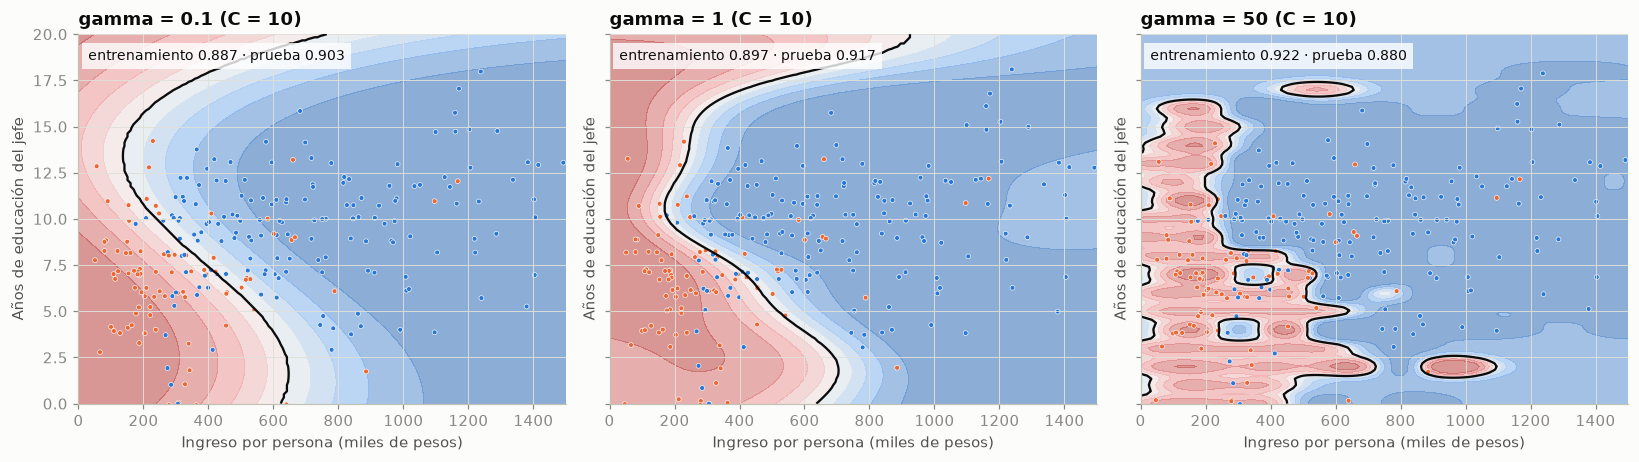

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, g in zip(axs, [0.1, 1, 50]):
    m = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=10, gamma=g, probability=True, random_state=SEMILLA)).fit(X2tr, ytr)
    dibujar_mapa(ax, m, f'gamma = {g} (C = 10)')
    ax.text(30, 18.6, f'entrenamiento {accuracy_score(ytr, m.predict(X2tr)):.3f} · prueba {accuracy_score(yte, m.predict(X2te)):.3f}',
            fontsize=9, color=TINTA, bbox=dict(fc='white', ec='none', alpha=.8))
plt.tight_layout(); plt.show()

El kernel RBF permite fronteras curvas, y **gamma** controla cuánto se curvan:

- **gamma = 0,1:** frontera suave, una curva amplia. 0,887 en entrenamiento y 0,903 en prueba.
- **gamma = 1:** la frontera se dobla para seguir a los hogares pobres de bajo ingreso, sobre todo con poca educación. Es el mejor de los tres en prueba: **0,917** (0,897 en entrenamiento).
- **gamma = 50:** cada hogar influye solo a muy corta distancia y aparecen **islas**. Sube el entrenamiento (0,922) y cae la prueba (0,880): **sobreajuste**, como kNN con k = 1.

## 6. Elegir kernel, C y gamma con validación cruzada

Ahora con **todas las variables**. La búsqueda se hace con 5 pliegues del entrenamiento y el AUC; el escalado va dentro del `Pipeline`, así que en cada pliegue se ajusta solo con la parte de entrenamiento.

In [8]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
rejilla_h = [{'svc__kernel': ['linear'], 'svc__C': [0.01, 0.1, 1, 10]},
             {'svc__kernel': ['rbf'], 'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [0.001, 0.01, 0.1, 1]}]
busq = GridSearchCV(make_pipeline(StandardScaler(), SVC()), rejilla_h, cv=cv, scoring='roc_auc').fit(Xtr, ytr)
print('Mejor combinación:', {k.split('__')[1]: v for k, v in busq.best_params_.items()}, f'· AUC en validación cruzada = {busq.best_score_:.3f}')
res = pd.DataFrame(busq.cv_results_)
rbf = res[res['param_svc__kernel'] == 'rbf'].pivot_table(index='param_svc__C', columns='param_svc__gamma', values='mean_test_score')
print('\nKernel lineal, AUC según C:', res[res['param_svc__kernel'] == 'linear'].set_index('param_svc__C')['mean_test_score'].round(3).to_dict())
print('\nKernel RBF, AUC (filas: C · columnas: gamma):'); rbf

Mejor combinación: {'C': 10, 'kernel': 'linear'} · AUC en validación cruzada = 0.944

Kernel lineal, AUC según C: {0.01: 0.921, 0.1: 0.93, 1.0: 0.942, 10.0: 0.944}

Kernel RBF, AUC (filas: C · columnas: gamma):


param_svc__gamma,0.001,0.010,0.100,1.000
param_svc__C,,,,
0.100,0.900,0.900,0.884,0.771
1.000,0.903,0.923,0.901,0.771
10.000,0.926,0.932,0.875,0.764
100.000,0.938,0.913,0.860,0.764


Con las 19 variables, la búsqueda eligió el **kernel lineal con C = 10**, con un AUC de validación de **0,944**:

- **Kernel lineal:** el AUC sube con C, de 0,921 (C = 0,01) a 0,944 (C = 10).
- **Kernel RBF:** su mejor combinación (C = 100 y gamma = 0,001) llega a 0,938.
- **Con gamma = 1** el RBF se derrumba (de 0,764 a 0,771) por sobreajuste, con cualquier C.

Con todas las variables escaladas, la frontera entre pobres y no pobres es casi una recta, y la flexibilidad del kernel no se aprovecha. Es lo mismo que mostró la clase: el SVM lineal queda casi igual que la regresión logística.

## 7. Del puntaje a la probabilidad

El SVM da un **puntaje** (`decision_function`): su signo dice de qué lado de la frontera cae el hogar y su tamaño, qué tan lejos. Para tener una probabilidad, `probability=True` ajusta una curva S sobre ese puntaje (escalado de Platt), con validación cruzada interna.

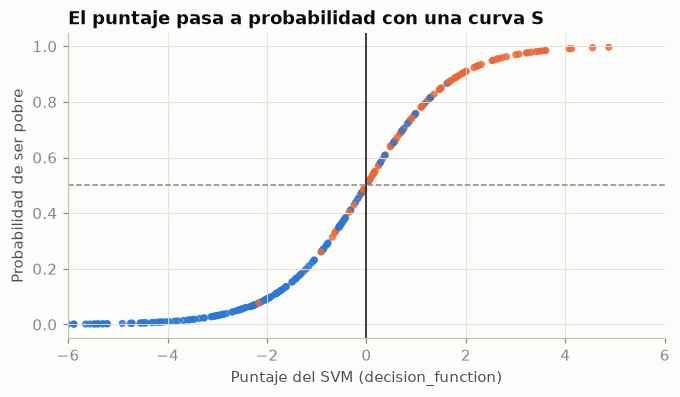

Hogares de prueba dentro de la calle (|puntaje| < 1): 77 de 300
Coincidencia entre «puntaje > 0» y «probabilidad ≥ 0,5»: 100.0%


In [9]:
p_ = busq.best_params_
svm = make_pipeline(StandardScaler(), SVC(kernel=p_['svc__kernel'], C=p_['svc__C'], gamma=p_.get('svc__gamma', 'scale'), probability=True, random_state=SEMILLA)).fit(Xtr, ytr)
punt, p_svm = svm.decision_function(Xte), svm.predict_proba(Xte)[:, 1]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.scatter(punt, p_svm, s=14, c=np.where(yte == 1, NARANJA, AZUL), alpha=.8)
ax.axvline(0, color=TINTA, lw=1); ax.axhline(.5, color=GRIS, ls='--', lw=1); ax.set_xlim(-6, 6)
ax.set_xlabel('Puntaje del SVM (decision_function)'); ax.set_ylabel('Probabilidad de ser pobre'); ax.set_title('El puntaje pasa a probabilidad con una curva S'); plt.show()
print(f'Hogares de prueba dentro de la calle (|puntaje| < 1): {(np.abs(punt) < 1).sum()} de {len(punt)}')
print(f'Coincidencia entre «puntaje > 0» y «probabilidad ≥ 0,5»: {np.mean((punt > 0) == (p_svm >= .5)):.1%}')

El gráfico muestra cómo `probability=True` convierte el puntaje en probabilidad:

- Los puntajes muy negativos (hogares muy lejos de la frontera, del lado «no pobre») tienen una probabilidad casi 0.
- Los positivos altos tienen una probabilidad casi 1.
- Alrededor del puntaje 0 la probabilidad cambia rápido.

**77 de los 300 hogares de prueba** quedan dentro de la calle (puntaje entre −1 y 1): son los casos dudosos. El criterio «puntaje > 0» y el criterio «probabilidad ≥ 0,5» clasifican igual al **100 %** de los hogares. La probabilidad sirve para mover el umbral y para calcular la curva ROC.

## 8. Métricas y curvas ROC frente a los demás modelos

Se comparan en **prueba** con la línea base, la logística, el árbol ajustado, el random forest y kNN, con los ajustes de sus prácticas.

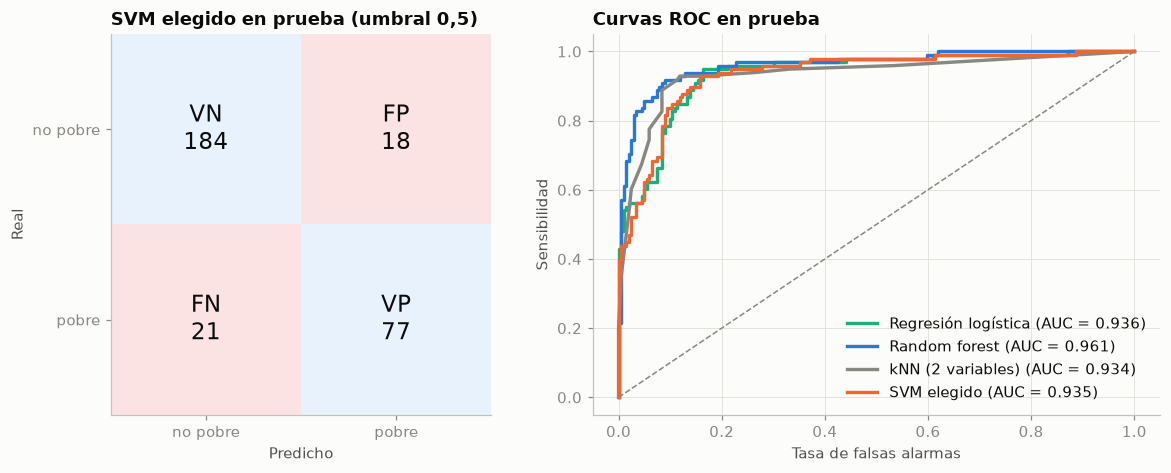

,exactitud,precisión,sensibilidad,F1,AUC
Línea base (nadie es pobre),0.673,0.000,0.000,0.000,0.500
Regresión logística,0.863,0.806,0.765,0.785,0.936
Árbol ajustado,0.917,0.854,0.898,0.876,0.954
Random forest,0.910,0.845,0.888,0.866,0.961
kNN (2 variables),0.887,0.827,0.827,0.827,0.934
SVM lineal,0.877,0.821,0.796,0.808,0.936
SVM elegido,0.870,0.811,0.786,0.798,0.935


In [10]:
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
arbol = GridSearchCV(DecisionTreeClassifier(random_state=SEMILLA), {'max_depth': [2, 3, 4, 5, 6, 8, None], 'min_samples_leaf': [1, 5, 10, 20]},
                     cv=cv, scoring='roc_auc').fit(Xtr, ytr).best_estimator_
bosque = RandomForestClassifier(n_estimators=300, max_features=0.5, min_samples_leaf=5, random_state=SEMILLA, n_jobs=-1).fit(Xtr, ytr)
knn = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()), {'kneighborsclassifier__n_neighbors': [5, 9, 15, 21, 31]}, cv=cv, scoring='roc_auc').fit(X2tr, ytr)
svm_lin = make_pipeline(StandardScaler(), SVC(kernel='linear', C=1, probability=True, random_state=SEMILLA)).fit(Xtr, ytr)
prob = {'Línea base (nadie es pobre)': np.zeros(len(yte)), 'Regresión logística': logit.predict_proba(Xte)[:, 1], 'Árbol ajustado': arbol.predict_proba(Xte)[:, 1],
        'Random forest': bosque.predict_proba(Xte)[:, 1], 'kNN (2 variables)': knn.predict_proba(X2te)[:, 1], 'SVM lineal': svm_lin.predict_proba(Xte)[:, 1], 'SVM elegido': p_svm}
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={'width_ratios': [1, 1.3]})
matriz(axs[0], yte, p_svm, 'SVM elegido en prueba (umbral 0,5)')
for nombre, color in [('Regresión logística', AQUA), ('Random forest', AZUL), ('kNN (2 variables)', GRIS), ('SVM elegido', NARANJA)]:
    fpr, tpr, _ = roc_curve(yte, prob[nombre]); axs[1].plot(fpr, tpr, color=color, lw=2.2, label=f'{nombre} (AUC = {roc_auc_score(yte, prob[nombre]):.3f})')
axs[1].plot([0, 1], [0, 1], color=GRIS, ls='--', lw=1); axs[1].set_xlabel('Tasa de falsas alarmas'); axs[1].set_ylabel('Sensibilidad')
axs[1].set_title('Curvas ROC en prueba'); axs[1].legend(loc='lower right'); plt.tight_layout(); plt.show()
pd.DataFrame({k: metricas(yte, p) for k, p in prob.items()}).T

En prueba, frente a la línea base (exactitud 0,673):

| Modelo | Exactitud | Sensibilidad | AUC |
|---|---|---|---|
| Regresión logística | 0,863 | 0,765 | 0,936 |
| Árbol ajustado | **0,917** | **0,898** | 0,954 |
| Random forest | 0,910 | 0,888 | **0,961** |
| kNN (2 variables) | 0,887 | 0,827 | 0,934 |
| SVM lineal (C = 1) | 0,877 | 0,796 | 0,936 |
| **SVM elegido** (lineal, C = 10) | 0,870 | 0,786 | 0,935 |

La matriz del SVM elegido: de los 98 hogares pobres de prueba encuentra a **77** y se le escapan **21**; de los 202 no pobres, señala por error a **18**.

El SVM queda prácticamente empatado con la logística (AUC 0,935 frente a 0,936): los dos trazan una frontera recta con las variables escaladas. Los modelos de árboles ganan porque los datos tienen umbrales e interacciones que una recta no captura.

## 9. Entrenamiento frente a prueba

In [11]:
pd.DataFrame({'SVM elegido · entrenamiento': metricas(ytr, svm.predict_proba(Xtr)[:, 1]), 'SVM elegido · prueba': metricas(yte, p_svm),
              'SVM lineal · entrenamiento': metricas(ytr, svm_lin.predict_proba(Xtr)[:, 1]), 'SVM lineal · prueba': metricas(yte, prob['SVM lineal'])}).T

,exactitud,precisión,sensibilidad,F1,AUC
SVM elegido · entrenamiento,0.892,0.835,0.838,0.836,0.951
SVM elegido · prueba,0.870,0.811,0.786,0.798,0.935
SVM lineal · entrenamiento,0.890,0.832,0.834,0.833,0.951
SVM lineal · prueba,0.877,0.821,0.796,0.808,0.936


El SVM elegido pierde poco de entrenamiento a prueba: exactitud **0,892 y 0,870**, y AUC 0,951 y 0,935. El SVM lineal con C = 1 se comporta igual (AUC 0,951 y 0,936). No hay sobreajuste importante, lo esperable en un modelo con frontera recta.

## Conclusiones

| Pregunta | Respuesta con estos datos |
|---|---|
| ¿Qué hace un SVM? | Busca la frontera con la **calle más ancha** entre los dos grupos |
| ¿Qué son los vectores de soporte? | Los hogares sobre el borde de la calle o dentro de ella. En el caso separable bastan 3 de 60 para definir la frontera |
| ¿Hay que escalar? | Sí: sin escalar, el SVM RBF acierta 0,683 (casi la línea base); escalado, 0,913 |
| ¿Qué hace C? | Con C = 0,01 la calle es tan ancha que el modelo subajusta (0,810 en prueba); desde C = 1 se estabiliza |
| ¿Qué hace gamma? | Con gamma = 50 aparecen islas y sobreajuste (0,922 en entrenamiento, 0,880 en prueba) |
| ¿Qué eligió la validación cruzada? | Kernel lineal con C = 10 (AUC 0,944); el mejor RBF llegó a 0,938 |
| ¿Frente a los demás? | AUC en prueba: SVM 0,935, logística 0,936, kNN 0,934, árbol 0,954, random forest 0,961 |

El SVM es un buen modelo de **frontera**: con el kernel adecuado se adapta a fronteras rectas o curvas, y depende solo de los hogares difíciles. Con estos datos, la frontera es casi recta y el SVM se comporta como una regresión logística. Su costo es que no da probabilidades directas ni efectos fáciles de leer, y que se vuelve lento con cientos de miles de datos.

## Retos

1. **Vectores de soporte que cambian todo.** En el caso separable de la sección 2, quite uno de los 3 vectores de soporte y vuelva a entrenar. ¿Cambia la frontera? Quite ahora un hogar que no sea vector de soporte.
2. **Desbalance.** Use `class_weight='balanced'` en el SVM elegido. ¿Qué pasa con la sensibilidad y la precisión? ¿Por qué?
3. **Otro kernel.** Pruebe `kernel='poly'` con `degree=2` y `degree=3` en el plano ingreso × educación. ¿Cómo es la frontera?
4. **El umbral.** Con las probabilidades del SVM elegido, busque el umbral que encuentra al menos el 90 % de los hogares pobres. ¿Cuántas falsas alarmas cuesta?
5. **SVM de regresión.** Use `SVR` para predecir el `ingreso_pc` (en logaritmo) y compare su MAE con el de una regresión lineal.